# Field size and result unpredictability
### Analyst task · Question 4

**Finding:** larger fields are associated with more frequent favourite losses. The direction appears across the adequately supported contexts examined and persists after adjustment. Context-specific estimates vary, but this does not establish that every context changes the relationship.

**A useful distinction:** favourites win less often in larger fields, yet their win rate is a greater multiple of the random-selection benchmark. Absolute success and relative advantage answer different questions.

**Reading guide:** Sections 1–5 form the presentation narrative, with three main figures. The appendix contains context detail, coverage checks and secondary exploration. All calculations run from top to bottom.

**Inputs:** `q4_development.csv.gz`, `race_metadata.csv.gz`, `race_quality.csv.gz`. Requires pandas, NumPy, Matplotlib, SciPy, statsmodels and patsy in a Jupyter environment. Set the folder below; optional figure exports are controlled at the end.

## 1. Question and approach

**How does field size relate to result unpredictability, and is the relationship universal or context-specific?**

- **Unit:** one eligible race, weighted equally. Field size counts actual starters, including recognised non-finishers.
- **Metric:** favourite failure rate = the proportion of races in which the sole favourite did not win. This measures the success of a simple selection policy, not the full uncertainty of a race or surprise relative to market odds.
- **Population:** eligible single-favourite races from 2021–2025, following the audit's whole-race exclusions. Using these years preserves 2026 for the separate predictive task; Q4 itself does not require a train/test split.
- **Comparison:** overall field-size bands, followed by contrasts between **2–5 and 10–13 starters** within contexts. We report percentage-point differences, not causal effects.

Without odds, a strong and a marginal favourite are treated alike. A favourite losing need not be a surprising result.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 60)

INPUT_DIR_OVERRIDE = None
# Uncomment for your existing export folder:
# INPUT_DIR_OVERRIDE = Path(r"C:\Users\orman\OneDrive\Documents\horse-racing-assignment\outputs\audit_20261016_045639_187839")
# On your laptop, set the above to:
# Path(r"C:\Users\orman\OneDrive\Documents\horse-racing-assignment\outputs\audit_20261016_045639_187839")
FILES = ['q4_development.csv.gz', 'race_quality.csv.gz', 'race_metadata.csv.gz']
if INPUT_DIR_OVERRIDE is not None:
    INPUT_DIR = Path(INPUT_DIR_OVERRIDE).expanduser()
else:
    locations = [Path('.'), Path('upload'), Path('..')]
    valid = [p for p in locations if all((p/f).is_file() for f in FILES)]
    if not valid:
        raise FileNotFoundError('Set INPUT_DIR_OVERRIDE to the folder containing all three input files.')
    INPUT_DIR = valid[0]
for name in FILES:
    assert (INPUT_DIR/name).is_file(), f'Missing input: {name}'
df = pd.read_csv(INPUT_DIR/FILES[0], dtype={'race_instance_uid': 'string'}, parse_dates=['event_datetime'])
quality = pd.read_csv(INPUT_DIR/FILES[1], dtype={'race_instance_uid': 'string'})
metadata = pd.read_csv(INPUT_DIR/FILES[2], dtype={'race_instance_uid': 'string'})
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False,
    'axes.spines.right': False, 'font.size': 11, 'axes.titleweight': 'bold',
    'axes.labelcolor': '#334155', 'text.color': '#172b4d'})
BLUE, ORANGE = '#225ea8', '#d97706'
figures = {}


In [2]:
required = ['race_instance_uid', 'event_datetime', 'year', 'field_size',
            'race_type_code', 'country_code', 'favourite_won', 'favourite_lost',
            'favourite_count', 'winner_count', 'supplied_field_size', 'q4_candidate']
assert set(required).issubset(df.columns)
assert df[required].notna().all().all()
assert df['race_instance_uid'].is_unique
assert df['year'].between(2021, 2025).all()
assert df['event_datetime'].dt.year.eq(df['year']).all()
assert (df['field_size'].ge(2) & df['field_size'].mod(1).eq(0)).all()
assert df['field_size'].eq(df['supplied_field_size']).all()
assert df['favourite_count'].eq(1).all() and df['winner_count'].eq(1).all()
assert df['q4_candidate'].eq(True).all()
assert df['favourite_lost'].isin([0, 1]).all()
assert df['favourite_won'].isin([0, 1]).all()
assert (df['favourite_won'] + df['favourite_lost']).eq(1).all()
print(f'{len(df):,} unique eligible races; all hand-off checks passed.')
print(f"Observed dates: {df.event_datetime.min().date()} to {df.event_datetime.max().date()}")

assert metadata.race_instance_uid.is_unique and quality.race_instance_uid.is_unique
check = df.merge(metadata[['race_instance_uid', 'race_type_code', 'country_code', 'race_datetime']],
                 on='race_instance_uid', how='left', validate='one_to_one', suffixes=('', '_meta'), indicator=True)
assert check['_merge'].eq('both').all()
for col in ['race_type_code', 'country_code']:
    assert check[col].eq(check[col+'_meta']).all()
assert pd.to_datetime(check.race_datetime).eq(check.event_datetime).all()
new_columns = [c for c in metadata if c not in df.columns]
df = df.merge(metadata[['race_instance_uid']+new_columns], on='race_instance_uid', how='left', validate='one_to_one')
qdev = quality.loc[quality.year.between(2021, 2025)].copy()
assert set(qdev.loc[qdev.q4_candidate.eq(True), 'race_instance_uid']) == set(df.race_instance_uid)
BANDS = ['2–5', '6–9', '10–13', '14–19', '20+']
BINS = [1, 5, 9, 13, 19, np.inf]
df['field_size_band'] = pd.cut(df.field_size, BINS, labels=BANDS)

# Check fields before context analysis; missing class/prize remains missing.
assert df.distance_furlong.gt(0).all()
df['going_context'] = df.going_type_desc.fillna('Missing').astype(str)
df['class_context'] = df.race_class.map(lambda v: f'Class {int(v)}' if pd.notna(v) else 'Missing')
print('All eligible races matched metadata; no eligibility changes.')


55,267 unique eligible races; all hand-off checks passed.
Observed dates: 2021-10-08 to 2025-12-31
All eligible races matched metadata; no eligibility changes.


## 2. Overall relationship and random-selection benchmark

For a uniformly random pick among `n` starters, the win probability is `1/n`. We average **`1/n` across races**, not `1/mean(n)`. This benchmark does not assume equal true ability; it describes an uninformed selection policy.

The favourite's intervals are 95% Wilson intervals under an independent-race approximation. The benchmark is its exact expected success on the observed races. These intervals do not capture selection bias or all dependence between races.

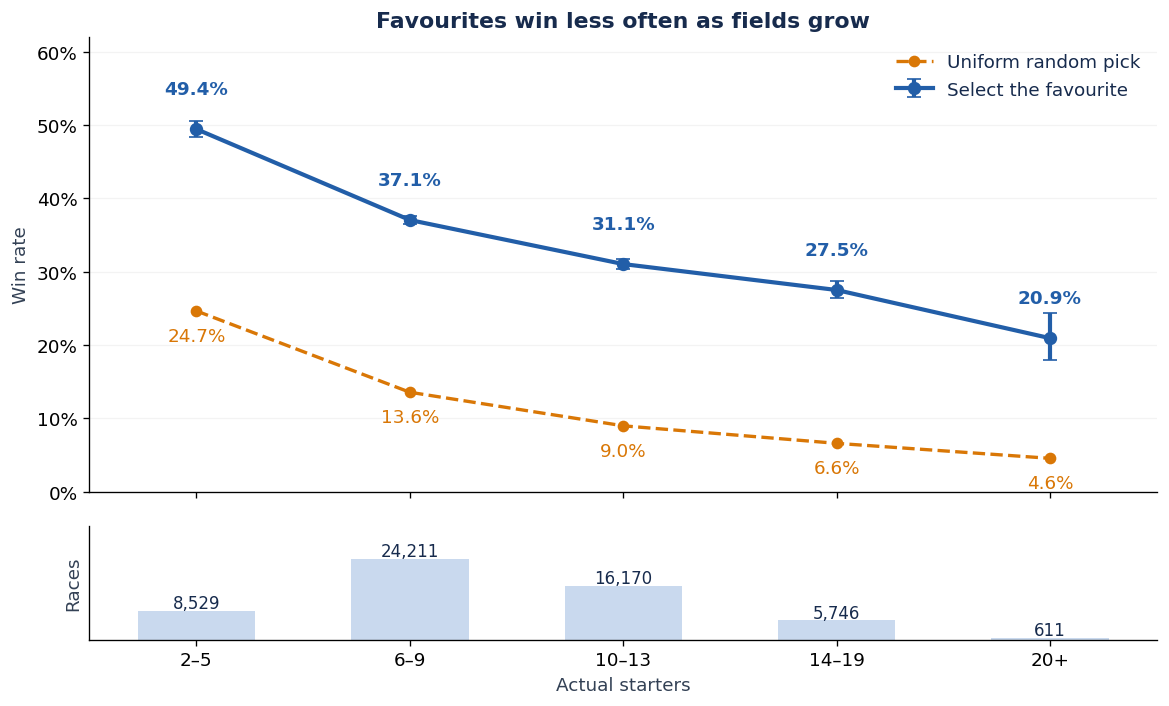

Favourite failure rises from **50.6%** to **79.1%** (**+28.5 percentage points**). The favourite/random win-rate ratio rises from **2.00×** to **4.59×**, while the absolute advantage narrows from **24.8** to **16.4 points**. The ratio does not mean larger races are easier to predict or that betting is profitable.

In [3]:
def summarise(data, groups):
    out = data.groupby(groups, observed=True, dropna=False).agg(
        races=('favourite_lost', 'size'), favourite_losses=('favourite_lost', 'sum'))
    n = out['races']
    p = out['favourite_losses'] / n
    z = 1.959963984540054
    denominator = 1 + z*z/n
    centre = (p + z*z/(2*n)) / denominator
    half = z * np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / denominator
    out['failure_rate'] = p
    out['ci_low'], out['ci_high'] = centre-half, centre+half
    return out

def show_rates(table):
    formatted = table.copy()
    for column in ['failure_rate', 'ci_low', 'ci_high']:
        formatted[column] = formatted[column].map(lambda v: f'{v:.1%}')
    display(formatted)


overall = summarise(df,'field_size_band')
df['random_win_probability'] = 1/df.field_size
benchmark = df.groupby('field_size_band',observed=True).agg(
    races=('favourite_won','size'), favourite_win_rate=('favourite_won','mean'),
    random_win_probability=('random_win_probability','mean'))
benchmark['advantage_pp'] = 100*(benchmark.favourite_win_rate-benchmark.random_win_probability)
benchmark['win_rate_ratio'] = benchmark.favourite_win_rate/benchmark.random_win_probability
x=np.arange(len(BANDS))
fig,(ax,counts)=plt.subplots(2,1,figsize=(10,6.2),sharex=True,
    gridspec_kw={'height_ratios':[4,1], 'hspace':.12})
ax.errorbar(x,benchmark.favourite_win_rate,
    yerr=[overall.ci_high-overall.failure_rate,overall.failure_rate-overall.ci_low],
    fmt='o-',lw=2.5,ms=7,color=BLUE,capsize=4,label='Select the favourite')
ax.plot(x,benchmark.random_win_probability,'o--',lw=2,color=ORANGE,label='Uniform random pick')
for i,row in enumerate(benchmark.itertuples()):
    ax.annotate(f'{row.favourite_win_rate:.1%}',(i,row.favourite_win_rate),
        xytext=(0,21),textcoords='offset points',ha='center',weight='bold',color=BLUE)
    ax.annotate(f'{row.random_win_probability:.1%}',(i,row.random_win_probability),
        xytext=(0,-18),textcoords='offset points',ha='center',color=ORANGE)
ax.set(title='Favourites win less often as fields grow',ylabel='Win rate',ylim=(0,.62))
ax.yaxis.set_major_formatter(PercentFormatter(1));ax.grid(axis='y',alpha=.15)
ax.legend(frameon=False,loc='upper right')
counts.bar(x,benchmark.races,color='#c9d9ee',width=.55)
for i,n in enumerate(benchmark.races): counts.text(i,n+800,f'{n:,}',ha='center',fontsize=10)
counts.set(xticks=x,xticklabels=BANDS,xlabel='Actual starters',ylabel='Races',ylim=(0,34000),yticks=[])
fig.subplots_adjust(left=.09,right=.98,top=.91,bottom=.1)
figures['01_favourite_vs_random']=fig
plt.show()
small,large=benchmark.iloc[0],benchmark.iloc[-1]
gap=100*(overall.iloc[-1].failure_rate-overall.iloc[0].failure_rate)
display(Markdown(f'Favourite failure rises from **{overall.iloc[0].failure_rate:.1%}** to '
 f'**{overall.iloc[-1].failure_rate:.1%}** (**+{gap:.1f} percentage points**). '
 f'The favourite/random win-rate ratio rises from **{small.win_rate_ratio:.2f}×** to '
 f'**{large.win_rate_ratio:.2f}×**, while the absolute advantage narrows from '
 f'**{small.advantage_pp:.1f}** to **{large.advantage_pp:.1f} points**. '
 'The ratio does not mean larger races are easier to predict or that betting is profitable.'))


## 3. Is the association confined to one race type?

Compare 10–13 with 2–5 starters. A positive difference means more favourite failures in the larger group. The common comparison avoids relying on sparse 20+ fields.

Intervals use a **date-cluster bootstrap**: resample complete race dates to preserve within-day dependence. This does not capture all dependence across dates. Race-type and going labels remain provider codes until their meanings are confirmed.

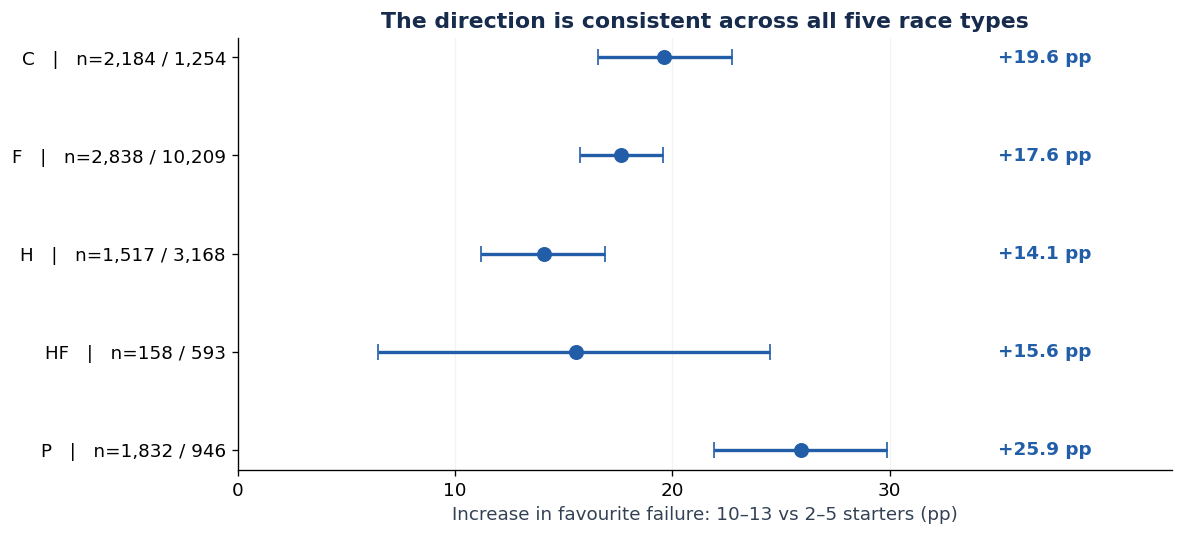

All five types show a positive increase: **14.1–25.9 points**. Labels show the numbers of small / medium-field races. The magnitude varies, but the point estimates alone do not establish different underlying effects.

In [4]:
# Reuse the same bootstrap date draws for all subgroup contrasts.
BOOTSTRAPS = 1000
rng = np.random.default_rng(42)
dates = np.sort(df.event_datetime.dt.normalize().unique())
date_draws = rng.multinomial(len(dates), np.full(len(dates),1/len(dates)), size=BOOTSTRAPS)
MIN_PER_BAND = 100

def context_contrasts(data, context):
    data=data.loc[data.field_size_band.isin(['2–5','10–13'])].copy()
    data['race_day']=data.event_datetime.dt.normalize()
    records=[]
    for (kind, label), group in data.groupby(['race_type_code',context], observed=True):
        samples={band:group.loc[group.field_size_band.eq(band)] for band in ['2–5','10–13']}
        sizes={band:len(part) for band,part in samples.items()}
        row={'race_type':kind,'context':str(label),'n_small':sizes['2–5'],'n_large':sizes['10–13']}
        row['supported']=min(sizes.values())>=MIN_PER_BAND
        if row['supported']:
            bootstrap_rates={}
            for band,part in samples.items():
                day=part.groupby('race_day').favourite_lost.agg(['size','sum']).reindex(dates,fill_value=0)
                bootstrap_rates[band]=(date_draws@day['sum'].to_numpy())/(date_draws@day['size'].to_numpy())
            contrasts=100*(bootstrap_rates['10–13']-bootstrap_rates['2–5'])
            row['difference_pp']=100*(samples['10–13'].favourite_lost.mean()-samples['2–5'].favourite_lost.mean())
            row['ci_low'],row['ci_high']=np.quantile(contrasts,[.025,.975])
        records.append(row)
    return pd.DataFrame(records)


df['all_context']='All races'
type_effect=context_contrasts(df,'all_context').set_index('race_type')
by_type=summarise(df,['race_type_code','field_size_band'])
type_comparison=type_effect[['difference_pp']].copy()
fig,ax=plt.subplots(figsize=(10,4.6))
y=np.arange(len(type_effect))
ax.errorbar(type_effect.difference_pp,y,
    xerr=[type_effect.difference_pp-type_effect.ci_low,type_effect.ci_high-type_effect.difference_pp],
    fmt='o',ms=8,color=BLUE,capsize=5,lw=2)
for i,row in enumerate(type_effect.itertuples()):
    ax.text(35,i,f'+{row.difference_pp:.1f} pp',va='center',weight='bold',color=BLUE)
labels=[f'{kind}   |   n={int(r.n_small):,} / {int(r.n_large):,}' for kind,r in type_effect.iterrows()]
ax.set(yticks=y,yticklabels=labels,xlim=(0,43),xticks=[0,10,20,30],
    xlabel='Increase in favourite failure: 10–13 vs 2–5 starters (pp)',
    title='The direction is consistent across all five race types')
ax.invert_yaxis();ax.axvline(0,color='#94a3b8',lw=1);ax.grid(axis='x',alpha=.15)
fig.tight_layout();figures['02_race_type_contrasts']=fig;plt.show()
display(Markdown(f'All five types show a positive increase: **{type_effect.difference_pp.min():.1f}–'
 f'{type_effect.difference_pp.max():.1f} points**. Labels show the numbers of small / medium-field races. '
 'The magnitude varies, but the point estimates alone do not establish different underlying effects.'))


## 4. Does accounting for measured context change the result?

Fit a binomial logistic model with **field-size band × race type**, country, year, going code and a separate log-distance slope for each type. Restrict this model to 2–19 starters because 20+ fields are sparse and absent in type P.

Within each type, average predicted probabilities over the same observed context mix under each field-size band. Compare these standardised probabilities between 2–5 and 10–13 starters. Date-clustered standard errors give delta-method intervals for the contrasts.

The model allows field-size associations to differ by **race type**. Going and distance are adjustments, not tests of field-size interactions with those variables. The model is explanatory, not the separate winner-prediction model, and its estimates remain observational and dependent on model assumptions.

Adjusted model: 54,656 races, 1,531 date clusters; converged.


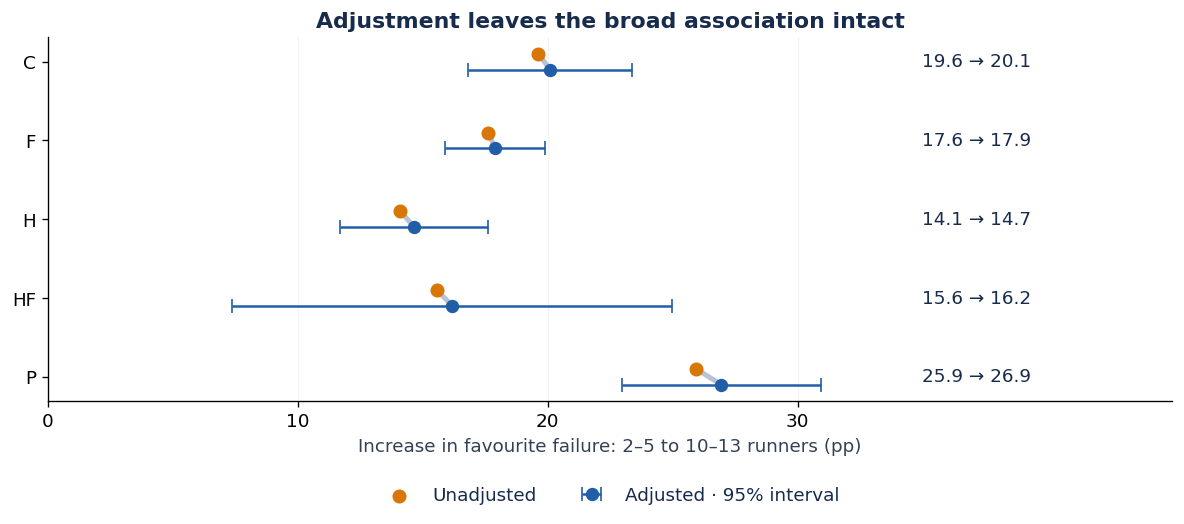

In [5]:
import statsmodels.api as sm
from patsy import build_design_matrices, dmatrices
from scipy.special import expit

adjusted = df.loc[df.field_size.le(19) & df.distance_furlong.gt(0)].copy()
adjusted['field_band'] = adjusted.field_size_band.astype(str)
adjusted['log_distance'] = np.log(adjusted.distance_furlong)
adjusted['day'] = adjusted.event_datetime.dt.normalize().astype(str)
# Exact codes retained; no outcome-dependent regrouping.
formula = ('favourite_lost ~ C(field_band)*C(race_type_code) + C(country_code) + C(year) '
           '+ C(going_context) + C(race_type_code):log_distance')
def fit_association(formula, data):
    y, design = dmatrices(formula, data, return_type='dataframe', NA_action='raise')
    fitted = sm.GLM(y, design, family=sm.families.Binomial()).fit(
        cov_type='cluster', cov_kwds={'groups':data.day})
    fitted.q4_design_info = design.design_info
    return fitted

model = fit_association(formula, adjusted)
assert model.converged
assert np.linalg.matrix_rank(model.model.exog)==model.model.exog.shape[1]
print(f'Adjusted model: {len(adjusted):,} races, {adjusted.day.nunique():,} date clusters; converged.')

def standardised_predictions(fitted, data, bands):
    beta=fitted.params.to_numpy();cov=fitted.cov_params().to_numpy()
    rows=[];contrasts=[]
    for kind, group in data.groupby('race_type_code'):
        estimates={}
        for band in bands:
            changed=group.copy();changed['field_band']=band
            design=np.asarray(build_design_matrices([fitted.q4_design_info],changed)[0])
            p=expit(design@beta)
            mean=p.mean();grad=(design*(p*(1-p))[:,None]).mean(axis=0)
            se=np.sqrt(max(0,grad@cov@grad))
            estimates[band]=(mean,grad)
            rows.append({'race_type':kind,'field_band':band,'failure_rate':mean,
                         'ci_low':max(0,mean-1.96*se),'ci_high':min(1,mean+1.96*se)})
        p0,g0=estimates['2–5'];p1,g1=estimates['10–13'];g=g1-g0
        se=np.sqrt(max(0,g@cov@g))
        contrasts.append({'race_type':kind,'difference_pp':100*(p1-p0),
                          'ci_low':100*(p1-p0-1.96*se),'ci_high':100*(p1-p0+1.96*se)})
    return pd.DataFrame(rows),pd.DataFrame(contrasts)

adjusted_rates,adjusted_contrasts=standardised_predictions(model,adjusted,BANDS[:4])

comparison=type_effect[['difference_pp']].rename(columns={'difference_pp':'unadjusted_pp'}).join(
    adjusted_contrasts.set_index('race_type').rename(columns={'difference_pp':'adjusted_pp'}))
fig,ax=plt.subplots(figsize=(10,4.6));y=np.arange(len(comparison))
for i,row in enumerate(comparison.itertuples()):
    ax.plot([row.unadjusted_pp,row.adjusted_pp],[i-.1,i+.1],color='#b8c4d3',lw=3,zorder=1)
ax.scatter(comparison.unadjusted_pp,y-.1,color=ORANGE,s=55,label='Unadjusted',zorder=3)
ax.errorbar(comparison.adjusted_pp,y+.1,
    xerr=[comparison.adjusted_pp-comparison.ci_low,comparison.ci_high-comparison.adjusted_pp],
    fmt='o',ms=7,color=BLUE,capsize=4,label='Adjusted · 95% interval',zorder=3)
for i,row in enumerate(comparison.itertuples()): ax.text(35,i,f'{row.unadjusted_pp:.1f} → {row.adjusted_pp:.1f}',va='center')
ax.set(yticks=y,yticklabels=comparison.index,xlim=(0,45),xticks=[0,10,20,30],
    xlabel='Increase in favourite failure: 2–5 to 10–13 runners (pp)',
    title='Adjustment leaves the broad association intact')
ax.invert_yaxis();ax.grid(axis='x',alpha=.15);ax.legend(frameon=False,loc='upper center',bbox_to_anchor=(.5,-.19),ncol=2)
fig.tight_layout();figures['03_before_after_adjustment']=fig;plt.show()


## 5. Answer and practical implications

**The association appears broad, not isolated to a single race type.** Larger fields have higher favourite failure rates, and accounting for measured context does not remove the pattern. Detailed going, class and distance comparisons in the appendix assess where this direction is also observed; they do not establish universal or causal effects.

**Interpretation:** selecting the favourite becomes less successful in absolute terms as fields grow. Its advantage over a random pick remains substantial, but depends on whether we measure an absolute difference or a ratio.

**Product relevance:** historical favourite success by field size and comparable race context could inform a racecard, accompanied by counts and uncertainty. It is not a calibrated probability for an individual race or evidence of profitable betting.

**Limits:** sole-favourite and quality exclusions create a selected population; odds are unavailable; exact field sizes can differ within broad bands; measured context does not cover all competitiveness factors. Source-code definitions need confirmation. Date clustering addresses only some dependence.

**Next priority:** complete the winner-prediction task. With more time, obtain odds and confirmed metadata definitions, investigate joint favourites and validate selected contextual differences in a separate period.

# Technical appendix
## A. Coverage and exact field sizes

Retention uses 2021–2025 races with runner records as the denominator. Excluded races' field sizes may themselves be unreliable. These figures document selection; they do not correct it.

In [6]:
qdev['field_size_band'] = pd.cut(qdev.field_size, [-np.inf, 1, 5, 9, 13, 19, np.inf],
                                    labels=['0–1']+BANDS)
retention = qdev.groupby('field_size_band', observed=True).agg(
    audited_races=('race_instance_uid','size'), shared_retained=('shared_valid','sum'),
    q4_retained=('q4_candidate','sum'))
retention['q4_retention_pct'] = 100*retention.q4_retained/retention.audited_races
retention['shared_retention_pct'] = 100*retention.shared_retained/retention.audited_races
retention['q4_retention_among_shared_pct'] = 100*retention.q4_retained/retention.shared_retained.replace(0,np.nan)
display(retention.round(1))

display(Markdown(f'Q4 retention falls from **{retention.loc["2–5","q4_retention_pct"]:.1f}%** '
 f'to **{retention.loc["20+","q4_retention_pct"]:.1f}%** across the smallest and largest competitive bands.'))
show_rates(overall)
shown=benchmark.copy()
for col in ['favourite_win_rate','random_win_probability']:shown[col]=shown[col].map(lambda v:f'{v:.1%}')
display(shown.round(2))


,audited_races,shared_retained,q4_retained,q4_retention_pct,shared_retention_pct,q4_retention_among_shared_pct
field_size_band,,,,,,
0–1,131,0,0,0.0,0.0,NaN
2–5,8986,8897,8529,94.9,99.0,95.9
6–9,26280,25989,24211,92.1,98.9,93.2
10–13,17902,17651,16170,90.3,98.6,91.6
14–19,6473,6335,5746,88.8,97.9,90.7
20+,764,667,611,80.0,87.3,91.6


Q4 retention falls from **94.9%** to **80.0%** across the smallest and largest competitive bands.

,races,favourite_losses,failure_rate,ci_low,ci_high
field_size_band,,,,,
2–5,8529,4312,50.6%,49.5%,51.6%
6–9,24211,15239,62.9%,62.3%,63.5%
10–13,16170,11149,68.9%,68.2%,69.7%
14–19,5746,4165,72.5%,71.3%,73.6%
20+,611,483,79.1%,75.6%,82.1%


,races,favourite_win_rate,random_win_probability,advantage_pp,win_rate_ratio
field_size_band,,,,,
2–5,8529,49.4%,24.7%,24.78,2.00
6–9,24211,37.1%,13.6%,23.48,2.73
10–13,16170,31.1%,9.0%,22.05,3.45
14–19,5746,27.5%,6.6%,20.90,4.16
20+,611,20.9%,4.6%,16.38,4.59


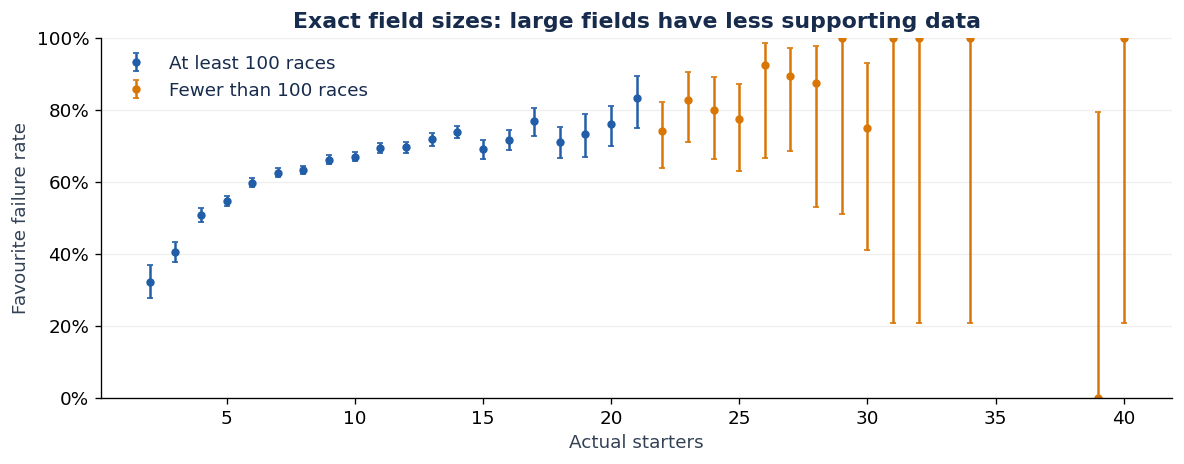

In [7]:
exact = summarise(df, 'field_size')
fig, ax = plt.subplots(figsize=(10, 4))
for sparse, colour, label in [(False, BLUE, 'At least 100 races'), (True, ORANGE, 'Fewer than 100 races')]:
    part = exact.loc[exact.races.lt(100).eq(sparse)]
    ax.errorbar(part.index, part.failure_rate,
                yerr=[part.failure_rate-part.ci_low, part.ci_high-part.failure_rate],
                fmt='o', color=colour, capsize=2, markersize=4, label=label)
ax.set(xlabel='Actual starters', ylabel='Favourite failure rate', ylim=(0, 1),
       title='Exact field sizes: large fields have less supporting data')
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(axis='y', alpha=.2)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()


## B. Going, class and distance

Exploratory contrasts use the same 2–5 versus 10–13 comparison. Require at least 100 races per band; all qualifying groups are shown. Intervals are pointwise date-bootstrap intervals, not simultaneous intervals across all comparisons.

- **Going:** retain exact source codes; do not infer surface or ground meanings from unconfirmed mappings.
- **Class:** GB races with recorded class only; all Irish class values are missing.
- **Distance:** up to three quantile bands per race type. Duplicate boundaries collapse; type P has many races at 24 furlongs. Displayed endpoints are rounded; intervals are right-closed except that the first includes the minimum.

Different point estimates suggest follow-up questions, not confirmed interaction effects. A context's 2–5 group may also contain a different mix of exact field sizes from another's.

Going code: 17 of 52 type/context groups meet the support threshold.
35 groups below threshold are retained in context_results for inspection.
GB race class: 12 of 22 type/context groups meet the support threshold.
10 groups below threshold are retained in context_results for inspection.
Within-type distance: 10 of 14 type/context groups meet the support threshold.
4 groups below threshold are retained in context_results for inspection.


,type,edges_furlongs,bands
0,C,"[15.1, 19.85, 23.414, 34.336]",3
1,F,"[4.973, 7.0, 8.182, 21.65]",3
2,H,"[15.0, 16.677, 20.186, 27.041]",3
3,HF,"[12.35, 16.0, 16.473, 20.682]",3
4,P,"[14.0, 24.0, 33.0]",2


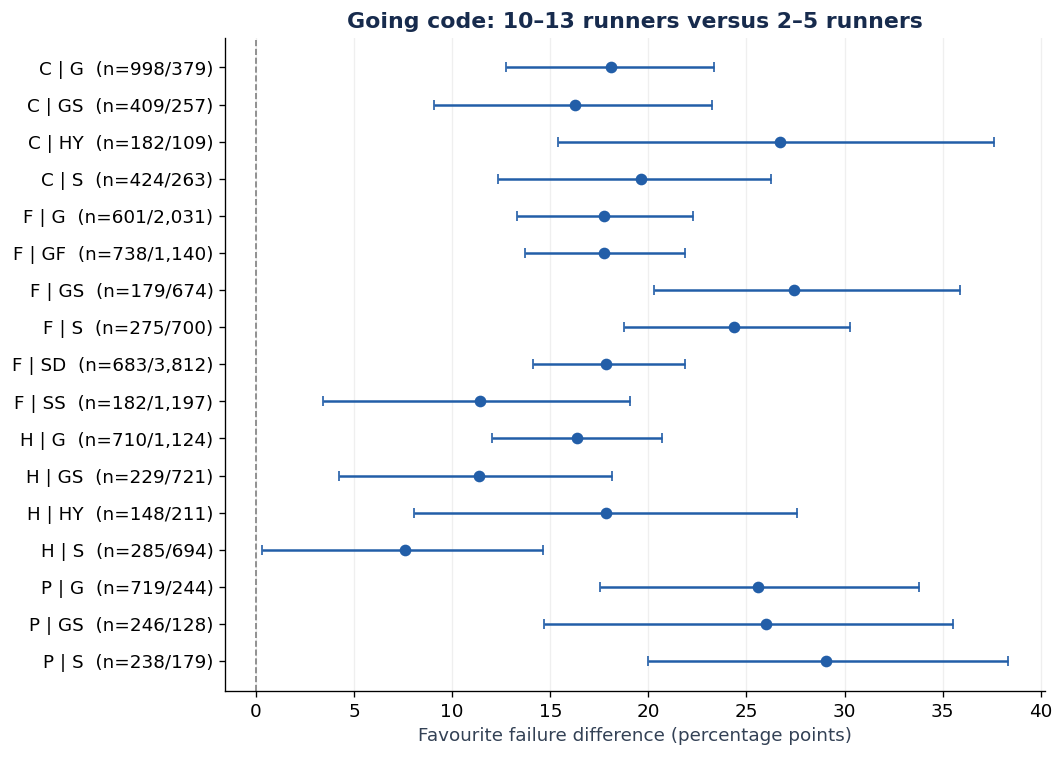

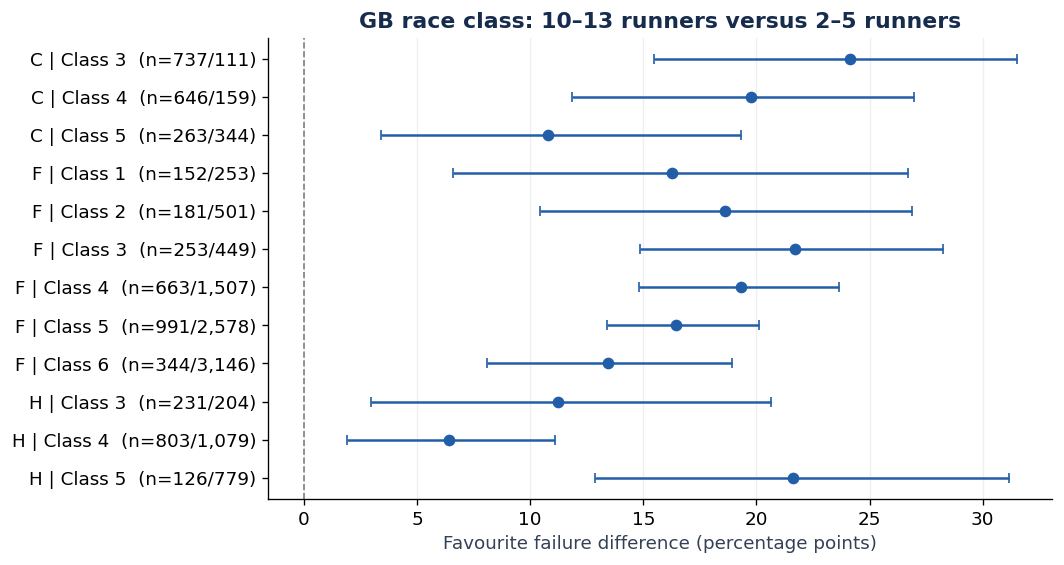

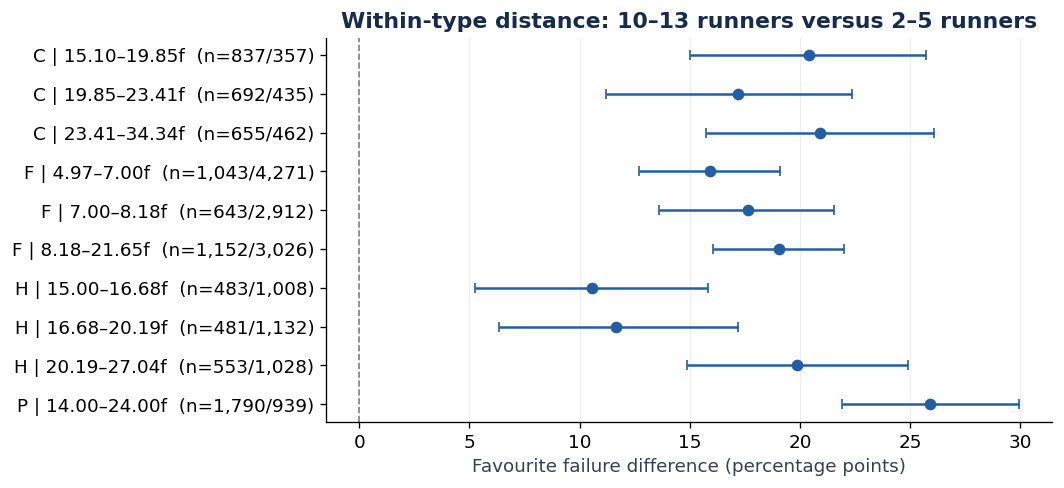

In [8]:
df['going_context'] = df.going_type_desc.fillna('Missing').astype(str)
df['class_context'] = df.race_class.map(lambda v: f'Class {int(v)}' if pd.notna(v) else 'Missing')
df['distance_context'] = pd.Series(index=df.index, dtype='object')
distance_cutpoints=[]
for kind, group in df.groupby('race_type_code'):
    valid_distance = group.distance_furlong.where(group.distance_furlong.gt(0))
    bands, edges = pd.qcut(valid_distance, 3, duplicates='drop', retbins=True)
    labels = {interval: f'{interval.left:.2f}–{interval.right:.2f}f' for interval in bands.cat.categories}
    bands = bands.cat.rename_categories(labels)
    df.loc[group.index, 'distance_context'] = bands.astype('object')
    distance_cutpoints.append({'type':kind, 'edges_furlongs': [round(v,3) for v in edges], 'bands':len(edges)-1})
display(pd.DataFrame(distance_cutpoints).round(2))

context_results={
 'Going code': context_contrasts(df,'going_context'),
 'GB race class': context_contrasts(df.loc[df.country_code.eq('GBR') & df.race_class.notna()],'class_context'),
 'Within-type distance': context_contrasts(df.loc[df.distance_context.notna()],'distance_context')}
for title,table in context_results.items():
    supported=table.loc[table.supported].sort_values(['race_type','context']).copy()
    print(f'{title}: {len(supported)} of {len(table)} type/context groups meet the support threshold.')
    # Full excluded subgroup counts remain in context_results and are exported.
    print(f'{(~table.supported).sum()} groups below threshold are retained in context_results for inspection.')
    # Full tables remain in context_results for inspection/export.
    if supported.empty: continue
    positions=np.arange(len(supported))
    fig, ax=plt.subplots(figsize=(9,max(3,0.32*len(supported)+1)))
    ax.errorbar(supported.difference_pp,positions,
                xerr=[supported.difference_pp-supported.ci_low,supported.ci_high-supported.difference_pp],
                fmt='o',color=BLUE,capsize=3)
    labels=[f'{r.race_type} | {r.context}  (n={r.n_small:,}/{r.n_large:,})' for r in supported.itertuples()]
    ax.set(yticks=positions,yticklabels=labels,xlabel='Favourite failure difference (percentage points)',
           title=f'{title}: 10–13 runners versus 2–5 runners')
    ax.axvline(0,color='grey',ls='--',lw=1);ax.invert_yaxis();ax.grid(axis='x',alpha=.2)
    plt.tight_layout();figures['context_'+str(len(figures))]=fig;plt.show()


In [9]:
context_overview=pd.DataFrame([
 {'context':name,'groups_examined':len(t),'supported_groups':int(t.supported.sum()),
  'positive_estimates':int(t.loc[t.supported,'difference_pp'].gt(0).sum()),
  'min_pp':t.loc[t.supported,'difference_pp'].min(),
  'max_pp':t.loc[t.supported,'difference_pp'].max()} for name,t in context_results.items()])
display(context_overview.round(1))
display(Markdown('The direction is positive in every supported subgroup examined. '
 'These are overlapping views of the same races, not independent replications. '
 'Sparse subgroups remain unassessed; variation in estimates does not establish which context modifies the association.'))


,context,groups_examined,supported_groups,positive_estimates,min_pp,max_pp
0,Going code,52,17,17,7.6,29.1
1,GB race class,22,12,12,6.4,24.1
2,Within-type distance,14,10,10,10.6,25.9


The direction is positive in every supported subgroup examined. These are overlapping views of the same races, not independent replications. Sparse subgroups remain unassessed; variation in estimates does not establish which context modifies the association.

## C. GB class sensitivity and model details

Compare models with and without class on the **same GB complete-class sample**. This separates the change from adding class from the change caused by restricting the sample. Standardised comparisons can extrapolate to sparse context combinations; the context mix is held constant within each type, not across types.

In [10]:
gb = adjusted.loc[adjusted.country_code.eq('GBR') & adjusted.race_class.notna()].copy()
gb_formula = ('favourite_lost ~ C(field_band)*C(race_type_code) + C(year) '
              '+ C(going_context) + C(race_type_code):log_distance')
gb_base=fit_association(gb_formula,gb)
gb_class=fit_association(gb_formula+' + C(class_context)',gb)
for fitted in [gb_base,gb_class]:
    assert fitted.converged
    assert np.linalg.matrix_rank(fitted.model.exog)==fitted.model.exog.shape[1]
_,base_contrast=standardised_predictions(gb_base,gb,['2–5','10–13'])
_,class_contrast=standardised_predictions(gb_class,gb,['2–5','10–13'])
class_sensitivity=base_contrast[['race_type','difference_pp']].rename(columns={'difference_pp':'without_class_pp'}).merge(
 class_contrast.rename(columns={'difference_pp':'with_class_pp'}),on='race_type',validate='one_to_one')
print(f'GB class sensitivity: {len(gb):,} races; all models use this same sample.')
display(class_sensitivity.round(1))

display(Markdown(f'Adding class changes the within-type contrasts by at most '
 f'**{(class_sensitivity.with_class_pp-class_sensitivity.without_class_pp).abs().max():.1f} percentage points**.'))
display(comparison.round(1))
# Optional detailed coefficients: model.summary()


GB class sensitivity: 38,909 races; all models use this same sample.


,race_type,without_class_pp,with_class_pp,ci_low,ci_high
0,C,16.7,17.1,13.1,21.0
1,F,18.3,17.6,15.5,19.8
2,H,13.1,13.3,10.0,16.6
3,HF,21.6,21.5,11.3,31.7


Adding class changes the within-type contrasts by at most **0.7 percentage points**.

,unadjusted_pp,adjusted_pp,ci_low,ci_high
race_type,,,,
C,19.6,20.1,16.8,23.4
F,17.6,17.9,15.9,19.9
H,14.1,14.7,11.7,17.6
HF,15.6,16.2,7.4,25.0
P,25.9,26.9,23.0,30.9


## D. Country and year checks

These are supporting consistency checks, not independent discoveries. 2021 covers October–December only. The detailed summary tables include intervals and counts.

country_code: 2–5 to 10–13 difference (percentage points)
year: 2–5 to 10–13 difference (percentage points)


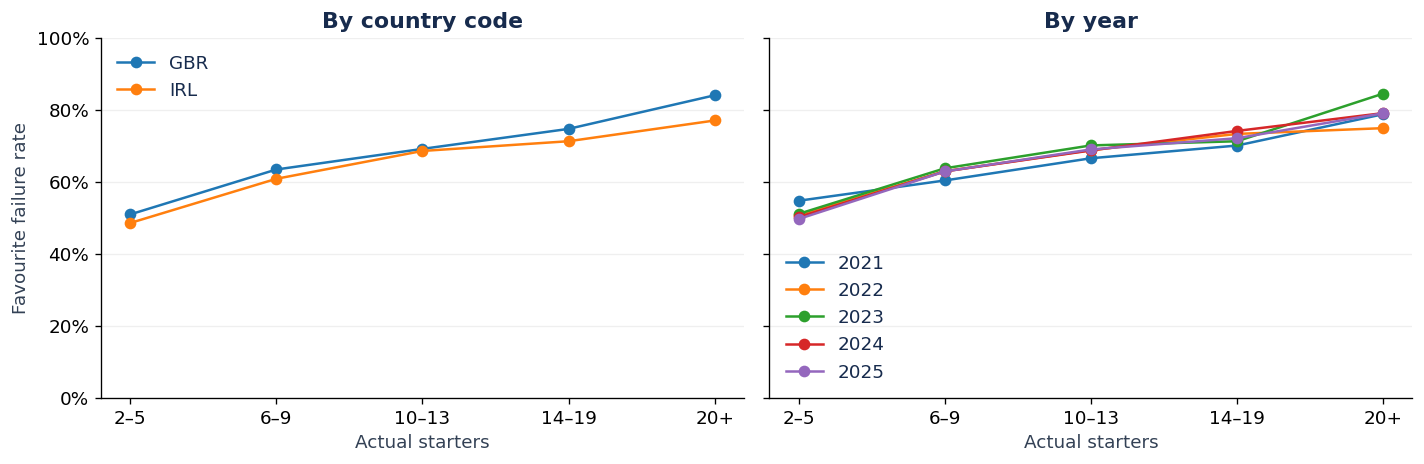

,difference_pp
country_code,
GBR,18.2
IRL,20.0


,difference_pp
year,
2021,11.8
2022,18.1
2023,19.0
2024,18.5
2025,19.3


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
context_tables = {}
for ax, context in zip(axes, ['country_code', 'year']):
    table = summarise(df, [context, 'field_size_band'])
    context_tables[context] = table
    for value in sorted(df[context].unique()):
        part = table.loc[value].reindex(BANDS)
        ax.plot(np.arange(5), part.failure_rate, marker='o', label=str(value))
    ax.set(title=f'By {context.replace("_", " ")}', xticks=np.arange(5),
           xticklabels=BANDS, xlabel='Actual starters', ylim=(0, 1))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis='y', alpha=.2)
    ax.legend(frameon=False)
axes[0].set_ylabel('Favourite failure rate')
fig.tight_layout()
plt.show()

for context, table in context_tables.items():
    r = table.failure_rate.unstack('field_size_band')
    changes = 100*(r['10–13']-r['2–5'])
    print(f'{context}: 2–5 to 10–13 difference (percentage points)')
    display(changes.round(1).rename('difference_pp').to_frame())


## E. Prize money and recorded handicap tags

Prize is secondary, overlaps with race level, and has uneven coverage. Use positive GBP totals for GB and EUR totals for Ireland; define thirds within country and race type. No currency pooling or inflation adjustment is made.

The source includes unusually small positive totals. Values below 1,000 in the relevant currency are **flagged for a sensitivity check**, not automatically declared wrong. Compare the original analysis with one excluding flagged values and recomputing the prize cut points.

Handicap tags describe recorded labels: unknown or absent tags are not confirmed non-handicaps. This appendix is descriptive and does not establish contextual interactions.

In [12]:
df['prize_native']=np.where(df.country_code.eq('GBR'),df.prizes_total_gbp,df.prizes_total_eur)
df['prize_native']=df.prize_native.where(df.prize_native.gt(0))
df['low_prize_flag']=df.prize_native.lt(1000)
prize_flags=df.loc[df.low_prize_flag,['race_instance_uid','country_code','prize_native']]
display(prize_flags.groupby(['country_code','prize_native']).size().rename('flagged_races').to_frame())

def prize_analysis(data):
    work=data.copy();work['prize_context']=pd.Series(index=work.index,dtype='object')
    cuts=[];skipped=[]
    for (country,kind),group in work.groupby(['country_code','race_type_code']):
        valid=group.prize_native.dropna()
        if len(valid)<300 or valid.nunique()<3:
            skipped.append((country,kind,'Insufficient recorded prize data'));continue
        try:
            bands,edges=pd.qcut(valid,3,labels=['Lower third','Middle third','Upper third'],retbins=True)
        except ValueError:
            skipped.append((country,kind,'Tied quantile boundaries'));continue
        work.loc[valid.index,'prize_context']=[f'{country} | {v}' for v in bands.astype(str)]
        cuts.append({'country':country,'type':kind,'n':len(valid),'cut_1':edges[1],'cut_2':edges[2]})
    table=summarise(work.loc[work.prize_context.notna()],['race_type_code','prize_context','field_size_band'])
    rates=table.failure_rate.unstack('field_size_band');counts=table.races.unstack('field_size_band')
    result=pd.DataFrame({'n_small':counts['2–5'],'n_large':counts['10–13'],
                        'difference_pp':100*(rates['10–13']-rates['2–5'])})
    return result.loc[result[['n_small','n_large']].ge(100).all(axis=1)],pd.DataFrame(cuts),skipped

prize_comparison,prize_cutpoints,prize_skipped=prize_analysis(df)
prize_filtered,_,_=prize_analysis(df.loc[~df.low_prize_flag])
prize_sensitivity=prize_comparison[['difference_pp']].rename(columns={'difference_pp':'original_pp'}).join(
    prize_filtered[['difference_pp']].rename(columns={'difference_pp':'without_flagged_pp'}),how='outer')
prize_sensitivity['change_pp']=prize_sensitivity.without_flagged_pp-prize_sensitivity.original_pp
display(prize_comparison.round(1));display(prize_sensitivity.round(2))
print('Prize groups not analysed:',prize_skipped)
print(f'Largest absolute change among comparable supported groups: {prize_sensitivity.change_pp.abs().max():.2f} pp')
def handicap_record(value):
    if pd.isna(value): return 'Unknown / unrecorded'
    try: labels=json.loads(value)
    except (TypeError,ValueError): return 'Unknown / unrecorded'
    if not isinstance(labels,list): return 'Unknown / unrecorded'
    if 'Handicap' in labels: return 'Explicit Handicap tag'
    if not labels or 'Unknown' in labels: return 'Unknown / unrecorded'
    return 'Other recorded group tags'
df['handicap_record']=df.race_group_uid.map(handicap_record)
display(df.handicap_record.value_counts().rename('races').to_frame())
handicap_summary=summarise(df,['handicap_record','field_size_band'])
show_rates(handicap_summary)


Prize groups not analysed: [('GBR', 'P', 'Insufficient recorded prize data'), ('IRL', 'P', 'Insufficient recorded prize data')]
Largest absolute change among comparable supported groups: 0.07 pp


,,flagged_races
country_code,prize_native,
GBR,1.0,1
IRL,100.0,9


n_small  n_large  difference_pp
race_type_code prize_context                                      
C              GBR | Lower third     482.0    347.0           13.1
               GBR | Middle third    836.0    173.0           22.7
               GBR | Upper third     596.0    244.0           15.7
               IRL | Upper third     158.0    102.0           46.5
F              GBR | Lower third     692.0   3335.0           17.4
               GBR | Middle third    920.0   2805.0           17.1
               GBR | Upper third     971.0   2294.0           19.7
               IRL | Upper third     153.0    539.0            7.1
H              GBR | Lower third     339.0    906.0           16.8
               GBR | Middle third    515.0    822.0           11.0
               GBR | Upper third     453.0    530.0           11.3
               IRL | Upper third     162.0    239.0           20.9

original_pp  without_flagged_pp  change_pp
race_type_code prize_context                                                 
C              GBR | Lower third         13.07               13.07       0.00
               GBR | Middle third        22.69               22.69       0.00
               GBR | Upper third         15.70               15.70       0.00
               IRL | Upper third         46.46               46.46       0.00
F              GBR | Lower third         17.44               17.51       0.07
               GBR | Middle third        17.13               17.13       0.00
               GBR | Upper third         19.67               19.67       0.00
               IRL | Upper third          7.14                7.14       0.00
H              GBR | Lower third         16.78               16.78       0.00
               GBR | Middle third        11.05               11.05       0.00
               GBR | Upper third         11.30               11.30       0.00
               IRL | Upper third         20.87               20.87       0.00

,races
handicap_record,
Explicit Handicap tag,31357
Unknown / unrecorded,21216
Other recorded group tags,2694


races  favourite_losses  \
handicap_record           field_size_band                            
Explicit Handicap tag     2–5               3600              2076   
                          6–9              13944              9464   
                          10–13             9860              7257   
                          14–19             3545              2764   
                          20+                408               351   
Other recorded group tags 2–5                620               307   
                          6–9               1401               837   
                          10–13              502               331   
                          14–19              144               100   
                          20+                 27                19   
Unknown / unrecorded      2–5               4309              1929   
                          6–9               8866              4938   
                          10–13             5808              3561   
                          14–19             2057              1301   
                          20+                176               113   

                                          failure_rate ci_low ci_high  
handicap_record           field_size_band                              
Explicit Handicap tag     2–5                    57.7%  56.0%   59.3%  
                          6–9                    67.9%  67.1%   68.6%  
                          10–13                  73.6%  72.7%   74.5%  
                          14–19                  78.0%  76.6%   79.3%  
                          20+                    86.0%  82.3%   89.1%  
Other recorded group tags 2–5                    49.5%  45.6%   53.4%  
                          6–9                    59.7%  57.2%   62.3%  
                          10–13                  65.9%  61.7%   69.9%  
                          14–19                  69.4%  61.5%   76.4%  
                          20+                    70.4%  51.5%   84.1%  
Unknown / unrecorded      2–5                    44.8%  43.3%   46.3%  
                          6–9                    55.7%  54.7%   56.7%  
                          10–13                  61.3%  60.1%   62.6%  
                          14–19                  63.2%  61.1%   65.3%  
                          20+                    64.2%  56.9%   70.9%

## F. Export figures and tables

Set `EXPORT_RESULTS=True` to create a new folder with presentation figures as **300-dpi PNG and vector PDF**, supporting figures, tables and the enriched data. Figure filenames beginning `01`, `02` and `03` are the main presentation sequence. The source exports remain unchanged.

In [13]:
EXPORT_RESULTS=False
if EXPORT_RESULTS:
    output=Path('outputs')/('q4_'+pd.Timestamp.now().strftime('%Y%m%d_%H%M%S_%f'))
    output.mkdir(parents=True,exist_ok=False)
    for name,fig in figures.items():
        fig.savefig(output/f'{name}.png',dpi=300,bbox_inches='tight',facecolor='white')
        fig.savefig(output/f'{name}.pdf',bbox_inches='tight',facecolor='white')
    tables={'retention':retention,'overall':overall,'benchmark':benchmark,'by_type':by_type,
        'type_contrasts':type_effect,'adjusted_rates':adjusted_rates,'adjusted_comparison':comparison,
        'class_sensitivity':class_sensitivity,'context_overview':context_overview,
        'prize_comparison':prize_comparison,'prize_sensitivity':prize_sensitivity,
        'prize_flags':prize_flags,'prize_cutpoints':prize_cutpoints,'handicap_summary':handicap_summary}
    tables.update({f'context_{i}':t for i,t in enumerate(context_results.values(),1)})
    tables.update({f'by_{name}':t for name,t in context_tables.items()})
    for name,t in tables.items():t.to_csv(output/f'{name}.csv')
    df.to_csv(output/'q4_enriched.csv.gz',index=False,compression='gzip')
    (output/'model_summary.txt').write_text(model.summary().as_text(),encoding='utf-8')
    print('Exported:',output)
else:
    print('Optional exports disabled.')


Optional exports disabled.
